#Student Management System + SHAP
**Python for Data Science**

##1. Setup and unique dataset

In [3]:
import warnings, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

N_STUDENTS = 300
SEED = 20260431                     # use your roll number so your dataset is unique
CSV_FILE = "students_dataset.csv"

SUBJECTS = ["Python", "DataScience", "Maths", "DBMS"]
COLUMNS = ["StudentID", "Name", "Branch", "Semester", "Gender", "Attendance", "StudyHours",
           "Python", "DataScience", "Maths", "DBMS", "AssignmentScore", "Backlogs", "Mentoring"]

In [4]:
np.random.seed(SEED)
n = N_STUDENTS
data = pd.DataFrame({
    "StudentID": range(1001, 1001 + n),
    "Name": ["Student" + str(i) for i in range(1, n + 1)],
    "Branch": np.random.choice(["Computer", "IT", "Mechanical", "Civil"], n),
    "Semester": np.random.choice([3, 4, 5, 6, 7], n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Attendance": np.random.normal(75, 10, n).clip(40, 100).round(1),
    "StudyHours": np.random.normal(2.5, 1, n).clip(0.3, 6).round(1),
    "Mentoring": np.random.choice(["Yes", "No"], n),
})

# marks go up with attendance, study hours and mentoring (plus some randomness)
base = 12 + 0.4 * data["Attendance"] + 6 * data["StudyHours"] + 6 * (data["Mentoring"] == "Yes")
for subject in SUBJECTS:
    data[subject] = (base + np.random.normal(0, 8, n)).clip(0, 100).round(0)

data["AssignmentScore"] = (0.6 * data[SUBJECTS].mean(axis=1) + 25 + np.random.normal(0, 8, n)).clip(0, 100).round(0)
data["Backlogs"] = np.random.poisson(np.clip((60 - data[SUBJECTS].mean(axis=1)) / 12, 0.05, None)).clip(0, 6)

# add some missing values so that data cleaning has something to do
data.loc[np.random.choice(n, 10, replace=False), "AssignmentScore"] = np.nan
data.loc[np.random.choice(n, 8, replace=False), "StudyHours"] = np.nan
data.to_csv(CSV_FILE, index=False)

In [5]:
students = pd.read_csv(CSV_FILE)[COLUMNS]

print("Dataset shape:", students.shape)
display(students.head())

Dataset shape: (300, 14)


,StudentID,Name,Branch,Semester,Gender,Attendance,StudyHours,Python,DataScience,Maths,DBMS,AssignmentScore,Backlogs,Mentoring
0,1001,Student1,IT,5,Male,69.4,3.3,68.0,69.0,63.0,46.0,73.0,0,No
1,1002,Student2,Mechanical,7,Female,52.5,2.5,46.0,45.0,49.0,41.0,53.0,2,No
2,1003,Student3,Civil,6,Female,71.3,2.4,53.0,58.0,56.0,49.0,59.0,0,Yes
3,1004,Student4,Mechanical,4,Male,58.5,4.3,59.0,67.0,62.0,69.0,78.0,0,No
4,1005,Student5,Mechanical,3,Female,62.1,1.4,34.0,54.0,42.0,37.0,48.0,3,No


##2. Student Management System (CRUD with SQLite)

In [6]:
class StudentNotFound(Exception):
    pass

class StudentManager:
    def __init__(self, db="students.db"):
        self.conn = sqlite3.connect(db)

    def load(self, df):                                       # create the table from a DataFrame
        df.assign(RiskLevel=None).to_sql("students", self.conn, if_exists="replace", index=False)

    def add_student(self, student_id, **data):                # CREATE
        row = pd.DataFrame([{"StudentID": student_id, **data}])
        row.to_sql("students", self.conn, if_exists="append", index=False)

    def all_students(self, where="1=1", params=()):           # READ
        return pd.read_sql(f"SELECT * FROM students WHERE {where}", self.conn, params=params)

    def get_student(self, sid):
        df = self.all_students("StudentID = ?", (int(sid),))
        if df.empty:
            raise StudentNotFound(f"Student {sid} not found")
        return df.iloc[0]

    def search(self, name_part):
        return self.all_students("Name LIKE ?", (f"%{name_part}%",))

    def update_student(self, sid, **fields):                  # UPDATE
        self.get_student(sid)                                 # raises StudentNotFound if missing
        for column, value in fields.items():
            self.conn.execute(f"UPDATE students SET {column} = ? WHERE StudentID = ?", (value, int(sid)))
        self.conn.commit()

    def delete_student(self, sid):                            # DELETE
        self.get_student(sid)
        self.conn.execute("DELETE FROM students WHERE StudentID = ?", (int(sid),))
        self.conn.commit()

    def report_card(self, sid):
        s = self.get_student(sid)
        print(f"REPORT CARD | ID {int(s.StudentID)} | {s.Name} | {s.Branch}, Semester {int(s.Semester)}")
        for sub in SUBJECTS:
            print(f"  {sub:<12}{s[sub]:>5.0f}")
        print(f"  Average     {np.mean([s[x] for x in SUBJECTS]):>5.1f}")
        print(f"  Attendance {s.Attendance}% | Backlogs {s.Backlogs} | Risk: {s.RiskLevel or 'not assigned yet'}")

sms = StudentManager()
sms.load(students)
print("Students stored in database:", len(sms.all_students()))

Students stored in database: 300


In [7]:
# ---- CRUD demo ----
print("CREATE: add student 9999")
sms.add_student(9999, Name="Test Student", Branch="Computer", Semester=5, Gender="Male", Attendance=88.0,
                StudyHours=2.5, Python=70, DataScience=75, Maths=68, DBMS=72, AssignmentScore=80, Backlogs=0,
                Mentoring="No")
display(sms.get_student(9999).to_frame().T)

print("READ / SEARCH: students named 'Test'")
display(sms.search("Test")[["StudentID", "Name", "Branch", "Semester"]])

print("UPDATE: change attendance and branch")
sms.update_student(9999, Attendance=92.5, Branch="IT")
sms.report_card(9999)

print("DELETE: remove student 9999")
sms.delete_student(9999)
try:
    sms.get_student(9999)
except StudentNotFound as e:
    print("Exception handled ->", e)
print("Total students now:", len(sms.all_students()))

CREATE: add student 9999


,StudentID,Name,Branch,Semester,Gender,Attendance,StudyHours,Python,DataScience,Maths,DBMS,AssignmentScore,Backlogs,Mentoring,RiskLevel
0,9999,Test Student,Computer,5,Male,88.0,2.5,70.0,75.0,68.0,72.0,80.0,0,No,None


READ / SEARCH: students named 'Test'


,StudentID,Name,Branch,Semester
0,9999,Test Student,Computer,5


UPDATE: change attendance and branch
REPORT CARD | ID 9999 | Test Student | IT, Semester 5
  Python         70
  DataScience    75
  Maths          68
  DBMS           72
  Average      71.2
  Attendance 92.5% | Backlogs 0 | Risk: not assigned yet
DELETE: remove student 9999
Exception handled -> Student 9999 not found
Total students now: 300


##3. Data cleaning and feature engineering

In [8]:
df = sms.all_students().drop(columns="RiskLevel")
print("Missing values per column:")
print(df.isna().sum()[lambda s: s > 0])
print("Duplicate IDs:", df["StudentID"].duplicated().sum())

for col in ["AssignmentScore", "StudyHours"]:
    df[col] = df[col].fillna(df[col].median())

df["AvgMarks"] = df[SUBJECTS].mean(axis=1).round(1)
df["Result"] = np.where(df["AvgMarks"] >= 40, "Pass", "Fail")
display(df.describe().round(2).T)

Missing values per column:
StudyHours          8
AssignmentScore    10
dtype: int64
Duplicate IDs: 0


,count,mean,std,min,25%,50%,75%,max
StudentID,300.0,1150.50,86.75,1001.0,1075.75,1150.50,1225.25,1300.0
Semester,300.0,4.99,1.36,3.0,4.00,5.00,6.00,7.0
Attendance,300.0,73.82,10.81,40.1,66.80,73.75,81.03,100.0
StudyHours,300.0,2.51,0.96,0.3,1.90,2.50,3.10,5.7
Python,300.0,59.46,11.21,30.0,52.00,60.00,67.25,94.0
DataScience,300.0,59.34,11.75,31.0,52.00,59.00,67.00,100.0
Maths,300.0,59.74,11.99,20.0,51.75,60.00,67.00,93.0
DBMS,300.0,59.28,11.79,30.0,51.00,59.00,66.00,99.0
AssignmentScore,300.0,61.28,9.75,36.0,55.00,60.00,68.00,94.0
Backlogs,300.0,0.37,0.77,0.0,0.00,0.00,0.00,4.0


##4. Exploratory analysis and visualisation

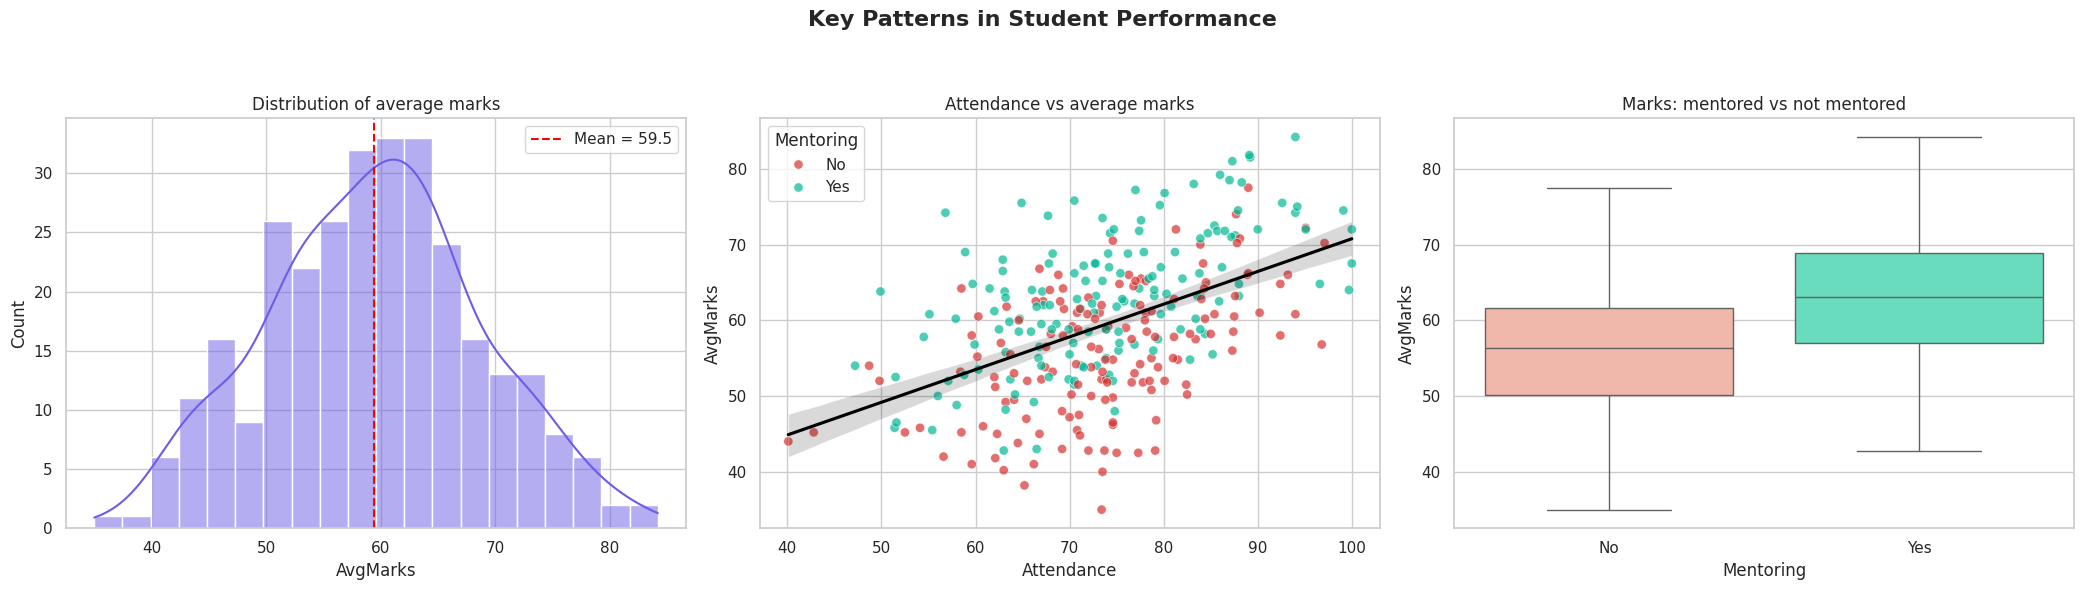

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle("Key Patterns in Student Performance", fontsize=16, fontweight="bold")

# 1. Distribution of average marks
sns.histplot(df["AvgMarks"], bins=20, kde=True, color="#6c5ce7", ax=ax[0])
ax[0].axvline(
    df["AvgMarks"].mean(),
    color="red",
    ls="--",
    label=f"Mean = {df['AvgMarks'].mean():.1f}"
)
ax[0].set_title("Distribution of average marks")
ax[0].legend()

# 2. Attendance vs average marks
sns.scatterplot(
    data=df,
    x="Attendance",
    y="AvgMarks",
    hue="Mentoring",
    palette={"Yes": "#00b894", "No": "#d63031"},
    alpha=0.7,
    s=45,
    ax=ax[1]
)
sns.regplot(
    data=df,
    x="Attendance",
    y="AvgMarks",
    scatter=False,
    color="black",
    ax=ax[1]
)
ax[1].set_title("Attendance vs average marks")

# 3. Marks: mentored vs not mentored
sns.boxplot(
    data=df,
    x="Mentoring",
    y="AvgMarks",
    hue="Mentoring",
    palette={"Yes": "#55efc4", "No": "#fab1a0"},
    legend=False,
    ax=ax[2]
)
ax[2].set_title("Marks: mentored vs not mentored")

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

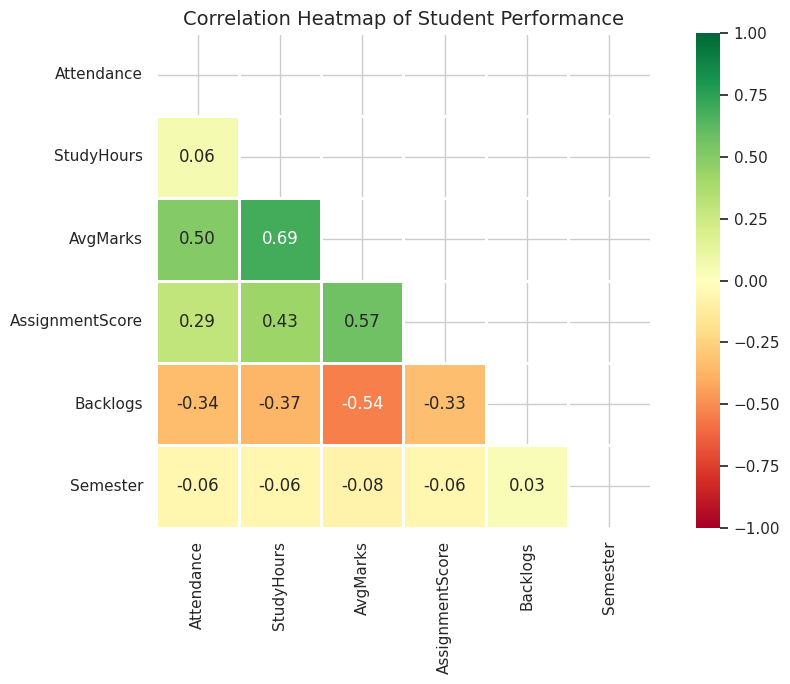

In [21]:
cols = [
    "Attendance",
    "StudyHours",
    "AvgMarks",
    "AssignmentScore",
    "Backlogs",
    "Semester"
]

corr = df[cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))

mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=1,
    linecolor="white",
    square=True
)

plt.title("Correlation Heatmap of Student Performance", fontsize=14)
plt.tight_layout()
plt.show()

##5. Beyond syllabus: SHAP (Explainable AI)

###train a model to predict at-risk students (scikit-learn)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
import shap

df["AtRisk"] = (df["AvgMarks"] < 50).astype(int)
df["Mentored"] = (df["Mentoring"] == "Yes").astype(int)

features = ["Attendance", "StudyHours", "Semester", "Mentored"]
X = df[features]
y = df["AtRisk"]
print("At-risk students:", y.sum(), "out of", len(y))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
model = RandomForestClassifier(n_estimators=200, max_depth=4, class_weight="balanced", random_state=SEED)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 2))
print("Test ROC-AUC :", round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 2))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))

At-risk students: 45 out of 300
Test accuracy: 0.91
Test ROC-AUC : 0.97
Confusion matrix:
 [[58  6]
 [ 1 10]]


###SHAP: overall explanation

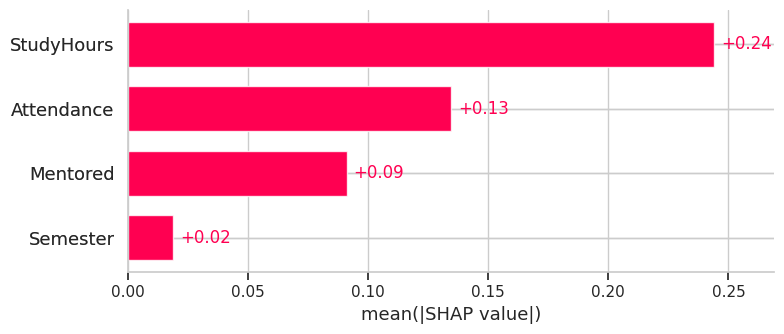

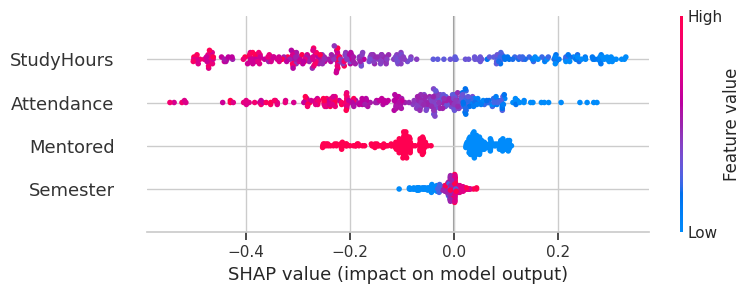

Average importance (mean |SHAP|):
StudyHours    0.244
Attendance    0.135
Mentored      0.091
Semester      0.019
dtype: float64


In [11]:
explainer = shap.TreeExplainer(model)
sv = explainer(X)
sv = sv[:, :, 1]

plt.figure(); shap.plots.bar(sv, show=False); plt.tight_layout(); plt.show()
plt.figure(); shap.plots.beeswarm(sv, show=False); plt.tight_layout(); plt.show()

print("Average importance (mean |SHAP|):")
print(pd.Series(abs(sv.values).mean(axis=0), index=features).round(3).sort_values(ascending=False))

###SHAP check: base value + SHAP values = model prediction

In [12]:
check = sv.base_values + sv.values.sum(axis=1)
print("Max difference:", float(abs(check - model.predict_proba(X)[:, 1]).max()))

Max difference: 1.887379141862766e-15


###SHAP: explain one student

Student189 -> risk score: 0.96
   Attendance  = 60.8   raises risk by 0.086
   StudyHours  = 1.0    raises risk by 0.289
   Semester    = 5.0    lowers risk by 0.003
   Mentored    = 0.0    raises risk by 0.087


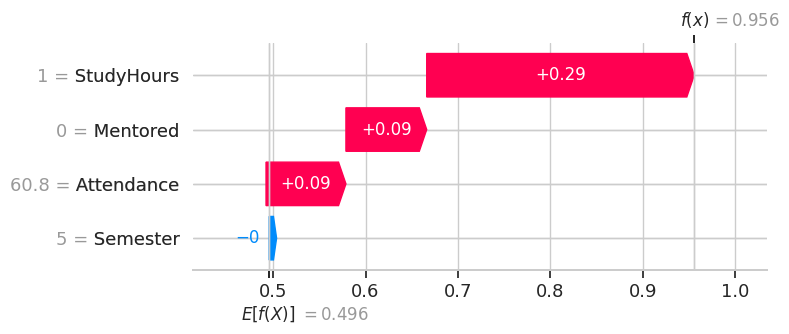

In [13]:
def explain_student(sid):
    i = df.index[df["StudentID"] == sid][0]
    print(df.loc[i, "Name"], "-> risk score:", round(model.predict_proba(X.iloc[[i]])[0, 1], 2))
    for feature, value in zip(features, sv.values[i]):
        print(f"   {feature:<11} = {X.iloc[i][feature]:<6} {'raises' if value > 0 else 'lowers'} risk by {abs(value):.3f}")
    plt.figure(); shap.plots.waterfall(sv[i], show=False); plt.tight_layout(); plt.show()

risk_score = model.predict_proba(X)[:, 1]
explain_student(int(df.loc[risk_score.argmax(), "StudentID"]))

##6. Connect the results back to the Student Management System

In [14]:
df["RiskScore"] = risk_score.round(2)
df["RiskLevel"] = np.where(risk_score >= 0.60, "High risk", np.where(risk_score >= 0.35, "Medium risk", "Low risk"))

for sid, level in zip(df["StudentID"], df["RiskLevel"]):
    sms.update_student(int(sid), RiskLevel=level)

def students_needing_attention():
    return sms.all_students("RiskLevel = 'High risk'")[
        ["StudentID", "Name", "Branch", "Attendance", "StudyHours", "Mentoring", "RiskLevel"]]

def advice(sid):
    level = sms.get_student(sid).RiskLevel
    tips = {"High risk": "Meet the student: extra classes, attendance follow-up and a study plan.",
            "Medium risk": "Regular practice tests and attendance monitoring.",
            "Low risk": "Encourage mentoring / advanced projects."}
    return tips[level]

def what_if(sid, **changes):
    i = df.index[df["StudentID"] == sid][0]
    row = X.iloc[[i]].copy()
    before = model.predict_proba(row)[0, 1]
    for feature, value in changes.items():
        row[feature] = value
    print(f"Risk before {before:.2f} -> after {model.predict_proba(row)[0, 1]:.2f}")

need = students_needing_attention()
print(f"{len(need)} students need attention:")
display(need.head(10))

sid = int(df.loc[risk_score.argmax(), "StudentID"])
sms.report_card(sid)
print("Advice:", advice(sid))
what_if(sid, Mentored=1)
what_if(sid, Mentored=1, Attendance=85)

51 students need attention:


,StudentID,Name,Branch,Attendance,StudyHours,Mentoring,RiskLevel
0,1002,Student2,Mechanical,52.5,2.5,No,High risk
1,1005,Student5,Mechanical,62.1,1.4,No,High risk
2,1008,Student8,Civil,58.0,1.4,Yes,High risk
3,1009,Student9,Civil,79.1,1.0,No,High risk
4,1031,Student31,Computer,72.0,1.0,No,High risk
5,1034,Student34,Civil,40.1,1.8,No,High risk
6,1039,Student39,Civil,58.5,1.6,No,High risk
7,1043,Student43,Civil,66.2,1.7,No,High risk
8,1046,Student46,Civil,72.3,1.4,No,High risk
9,1047,Student47,Computer,73.4,2.0,No,High risk


REPORT CARD | ID 1189 | Student189 | Computer, Semester 5
  Python         43
  DataScience    56
  Maths          33
  DBMS           52
  Average      46.0
  Attendance 60.8% | Backlogs 1 | Risk: High risk
Advice: Meet the student: extra classes, attendance follow-up and a study plan.
Risk before 0.96 -> after 0.62
Risk before 0.96 -> after 0.15


##7. Export results

In [15]:
df.to_csv("students_with_risk.csv", index=False)
need.to_csv("students_needing_attention.csv", index=False)
print("Saved: students_with_risk.csv, students_needing_attention.csv")
try:
    from google.colab import files
    files.download("students_with_risk.csv")
except ImportError:
    print("(Not in Colab - files are in the working folder)")

Saved: students_with_risk.csv, students_needing_attention.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>